# ki_twpa_structures — kinetic-inductance spirals and a TWPA-style finger-loaded line (legacy building blocks), on the Quantcore PDK

## 1 · What the chip is

**Request:** "import the kinetic-inductance and TWPA design chips to render, especially the spirals".

**What the library holds** (searched: `components/` and the sibling project folders, by name and content): **no KI or
TWPA chip script** — no `chip_*` file, notebook or GDS uses spirals, KI lines or a TWPA. The building blocks are:

| legacy source | what it draws | Quantcore cell |
|---|---|---|
| `components/pymacros/spiral.lym` ("MyLib" / `Spiral`) | Archimedean spiral path, `inner_r` → `outer_r`, pitch `width + spacing` per turn | `SpiralPath` (ported) |
| `components/python/draw.py::spiral` | spiral path by angle: Archimedean, Fermat, double Fermat (in/out) | `SpiralLine` (ported; ports `a` / `b`, own pocket, LOM line) |
| `components/python/cpwe.py::finger_line` (G. Long, Glasgow 2021) | CPW with interdigital fingers into both grounds (shunt C per unit length: the artificial line of a KI TWPA) | `CpweFingerLine` |
| `cpwe.py::meander_line`, `b_pad`, `tapper`, `term_open` | meandered CPW, bond pad, taper, open end | `CpweMeanderLine`, `CpweBondPad`, `CpweTaper`, `CpweOpenEnd` |
| `ustrip.py`, Cong `bondpad_ustrip.lym` | microstrip versions | not ported (decision: ignore microstrip) |

**This chip** (a structure sheet on the Quantcore PDK die, 7.5 mm, device ID `KI TWPA`) renders them: a **TWPA-style
line** — `CpweBondPad` → finger-loaded section → meandered section → finger-loaded section → `CpweBondPad` (10/6 µm
CPW-E) — and six **spiral inductors** (`SpiralLine`, metal on `base_metal_addition`, each in its own etched pocket):
four double-Fermat two-terminal inductors, one Fermat and one more double Fermat (longer arms), sized like KI lumped
inductors. It is not a reconstruction of a lost chip: if the KI / TWPA chip sources exist elsewhere, add them to
`components/` and they can be rebuilt like the other legacy chips.

| | the rebuild keeps | the Quantcore PDK changes |
|---|---|---|
| line | the snapped chain `PL → F1 → M1 → F2 → PR` (each `a` port onto the previous `b`: one continuous CPW-E), the legacy `b_pad` geometry (500 µm pad, 300 µm gap, exponential taper), the finger and meander cells | both pads at **`pad_edge` = 100 µm** from the die edge (fixed legacy sheet: PL 250 µm, PR 1234 µm): PL by `edge="auto"`, PR by **lengthening the meander `M1`** (the chain is snapped, so PR follows it; step 4) |
| spirals | the six `SpiralLine`s and their pockets | — |
| cheese | — (no source cheese) | the **PDK band** (`cheese: "auto"`) |
| placement | — | centred in the die (step 7; the sheet was 322 µm left of centre) |

### Rebuilt (2026-11-03)

A new notebook (a structure sheet: there is no KI / TWPA chip source). Open item: the KI film's sheet kinetic
inductance is not in the PDK (the L table of step 10 uses example values).

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- **Pads:** `PL` gets `edge="auto"` (outer etch 100 µm from the left die edge). `PR` is the end of a snapped chain,
  so it cannot be placed on its own: the chain is lengthened instead — the meander `M1` gets more periods (200 µm
  each in x) and the remainder as two straight leads (`lead`), computed from the measured gap, so that PR's outer
  etch lands exactly `pad_edge` = 100 µm from the right die edge. DRC `pad_edge` warnings: 2 → 0.
- **Centring:** with both pads at the rule, the line spans the die symmetrically; `L.center_circuit` (each axis only
  if > 50 µm off) then has nothing left to move.
- **Cheese:** no source cheese: the PDK band (`"auto"`).
- Educative layout: die → pads and the line → spirals → (no routes) → cheese and centring → DRC → LOM → (no FEM) →
  iterate → export → snapshots.

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import math
from quantcore_circuits.layouts.others.spirals import SpiralLine
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "ki_twpa_structures", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 14) and the centring of the content (step 7).

In [3]:
CHEESE_NOTE = 'PDK band (auto) — a structure sheet with no cheese of its own'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: PDK band (auto) — a structure sheet with no cheese of its own |

### The structures' numbers

The line: CPW-E 10/6 µm; the legacy `b_pad` of Cong's templates (`PAD`); the `cpwe.finger_line` unit cell (150
fingers, 2 µm wide, 10 µm long, 2 µm gaps); the `cpwe.meander_line` (r = 50 µm, 600 µm straights, 18 periods). The
spirals: `draw.spiral` parameters (type, `spiral_r` scale, width, end angle), each in a 20 µm pocket, on a 1100 µm
pitch at y = 5200 µm; the line at y = 2600 µm.

In [4]:
CPW = dict(a=10, b=6)                                           # CPW-E centre / gap (µm)
PAD = dict(pad_width=500, pad_gap=300, end_length=10, pad_length=50, taper_length=500, taper_type=3, weight=25) | CPW
FINGERS = dict(finger_gap=2, finger_length=10, finger_width=2, fingers=150) | CPW   # cpwe.finger_line unit cell
MEANDER = dict(meander_radius=50, meander_length=600, bias=0.5, meanders=18) | CPW   # cpwe.meander_line
#            name  type            spiral_r  width  end_angle  (µm / rad; draw.spiral parameters)
SPIRALS = [("S1", "double_fermat", 10, 1.0, 12 * math.pi),
           ("S2", "double_fermat", 16, 2.0, 12 * math.pi),
           ("S3", "double_fermat", 25, 3.0, 12 * math.pi),
           ("S4", "double_fermat", 8, 1.0, 8 * math.pi),
           ("S5", "fermat", 20, 2.0, 12 * math.pi),
           ("S6", "double_fermat", 12, 1.5, 16 * math.pi)]
POCKET = 20                                                      # own pocket beyond the spiral (µm)
def r_out(kind, sr, end):                                        # outer radius of the arm(s): spiral_r·sqrt(end_angle)
    return sr * math.sqrt(end)
SPIRAL_X = [1000 + 1100 * k for k in range(len(SPIRALS))]
Y_LINE, Y_SPIRAL = 2600.0, 5200.0

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die; the PDK frame (dicing L markers, alignment grids,
boundary, device ID `KI TWPA`) is drawn on every build; `cheese` stays `"auto"`, so the build draws the PDK band.

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


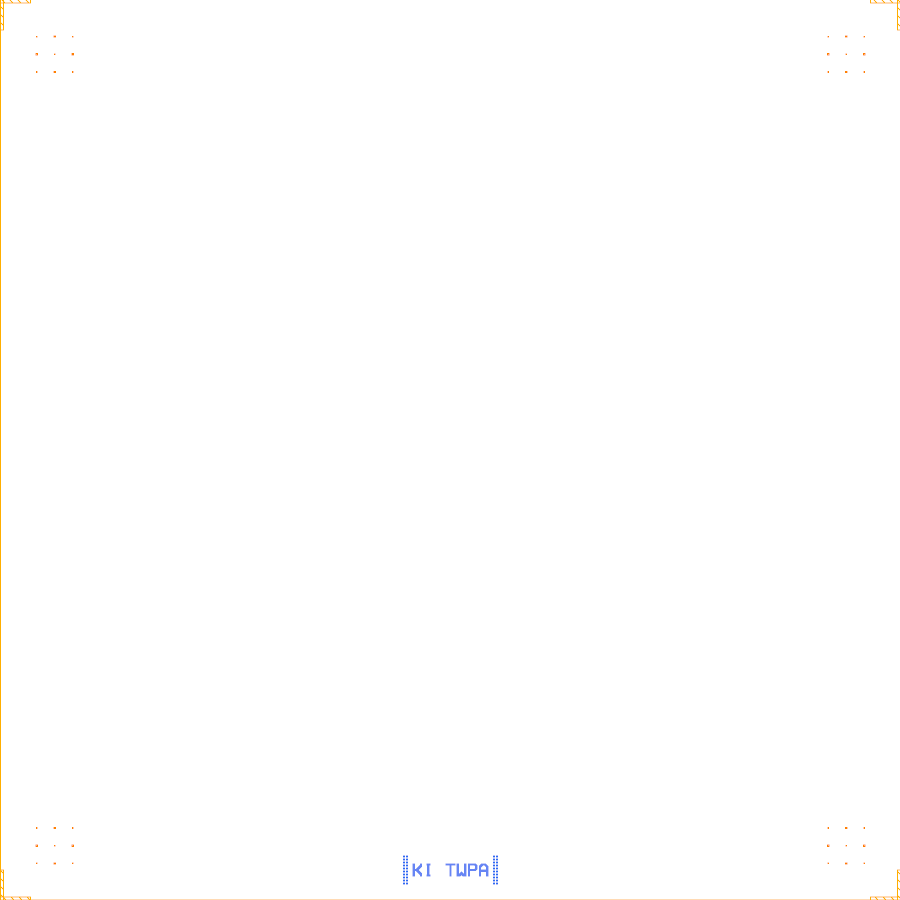

WindowsPath('build/legacy_steps/ki_twpa_structures_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "KI TWPA"}, live=LIVE)   # cheese "auto"
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule) and the TWPA-style line

The line is a chain of snapped cells, each `a` port onto the previous `b`: `PL` (`CpweBondPad`, port `a` at its
taper end, pointing +x) → `F1` (finger-loaded) → `M1` (meander) → `F2` (finger-loaded) → `PR` (the mirrored pad).
`PL` is placed with `edge="auto"`: its outer etch goes to **`pad_edge` = 100 µm** from the left die edge
(`get_pdk().frame.pad_edge`). `PR` follows the chain; with the fixed legacy sheet's sections it stops far short of the
right edge, as `L.edge_gaps` shows.

In [6]:
with d.batch():
    d.add("PL", "CpweBondPad", at=(250, Y_LINE), edge="auto", **PAD)            # port a at the taper end, +x
    d.add("F1", "CpweFingerLine", snap="a", to="PL.a", **FINGERS)              # finger-loaded (shunt C) section
    d.add("M1", "CpweMeanderLine", snap="a", to="F1.b", **MEANDER)             # meandered section
    d.add("F2", "CpweFingerLine", snap="a", to="M1.b", **FINGERS)
    d.add("PR", "CpweBondPad", snap="a", to="F2.b", mirror=True, **PAD)        # mirrored pad: port a at its origin, −x
GAP0 = L.edge_gaps(d)
print("pad etch → die edge (µm), legacy sections:", GAP0, "| rule:", get_pdk().frame.pad_edge)

pad etch → die edge (µm), legacy sections: {'PL': 100.0, 'PR': 1384.0} | rule: 100.0


**Lengthening the meander so PR lands at the rule.** A snapped pad cannot take `edge="auto"` (it is placed by its
`to=` port), so the chain itself must get longer by `GAP0["PR"] − pad_edge`. One section changes, the meander `M1`:
each extra meander period advances the line by 4 r = 200 µm in x (two half-turns), and the remainder below one
period goes into two equal straight leads (`lead`, the legacy `cpwe.quarter_wave`'s `resonator_excess`). The finger
sections and the pads keep their legacy geometry. `L.edge_gaps` then checks both pads.

chain +1284.0 µm: M1 meanders 18 → 24, lead 42.0 µm each side


pad etch → die edge (µm): {'PL': 100.0, 'PR': 100.0} | rule: 100.0


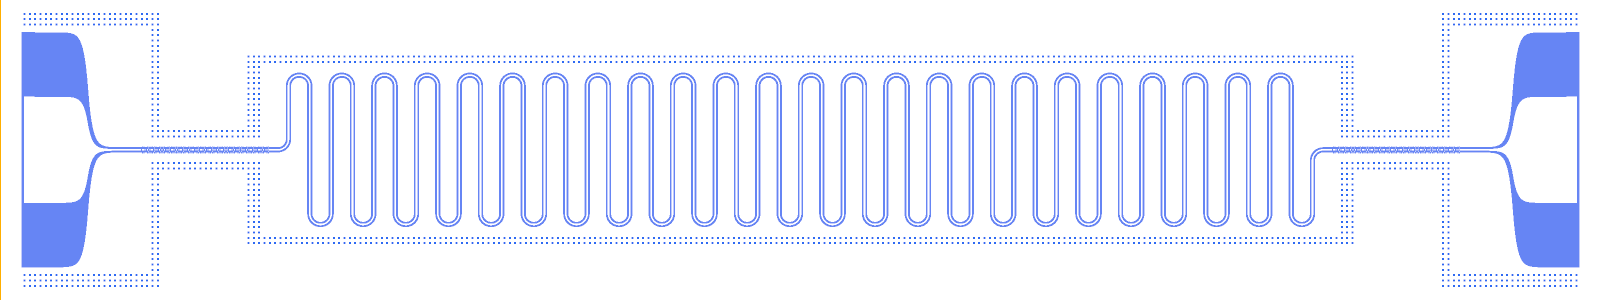

WindowsPath('build/legacy_steps/ki_twpa_structures_2_line.png')

In [7]:
EDGE = get_pdk().frame.pad_edge
EXTRA = GAP0["PR"] - EDGE                                    # how much longer the chain must get (µm)
PERIOD = 4 * MEANDER["meander_radius"]                       # x advance of one meander period (two half-turns)
N_ADD = int(EXTRA // PERIOD)
LEAD = round((EXTRA - N_ADD * PERIOD) / 2, 3)
d["M1"].set(meanders=MEANDER["meanders"] + N_ADD, lead=LEAD)
print(f"chain +{EXTRA:.1f} µm: M1 meanders {MEANDER['meanders']} → {MEANDER['meanders'] + N_ADD}, lead {LEAD} µm each side")
print("pad etch → die edge (µm):", L.edge_gaps(d), "| rule:", EDGE)
L.step_snapshot(d, "2_line", box=(0, 1900, L.W, 3300), size=(1600, 300), width=640)

## 5 · Components: six spiral inductors

`SpiralLine` (legacy `draw.spiral` by angle; `spiral_type` `double_fermat` = a two-terminal inductor with both ends
outside, `fermat` = one end in the centre; `spiral_r` scale, `end_angle`, `width`), drawn as metal with its own
etched pocket (`pocket_margin = 20` µm beyond the spiral). Each spiral has ports `a` / `b` (its two ends, not wired
on this sheet) and a LOM line of its drawn length.

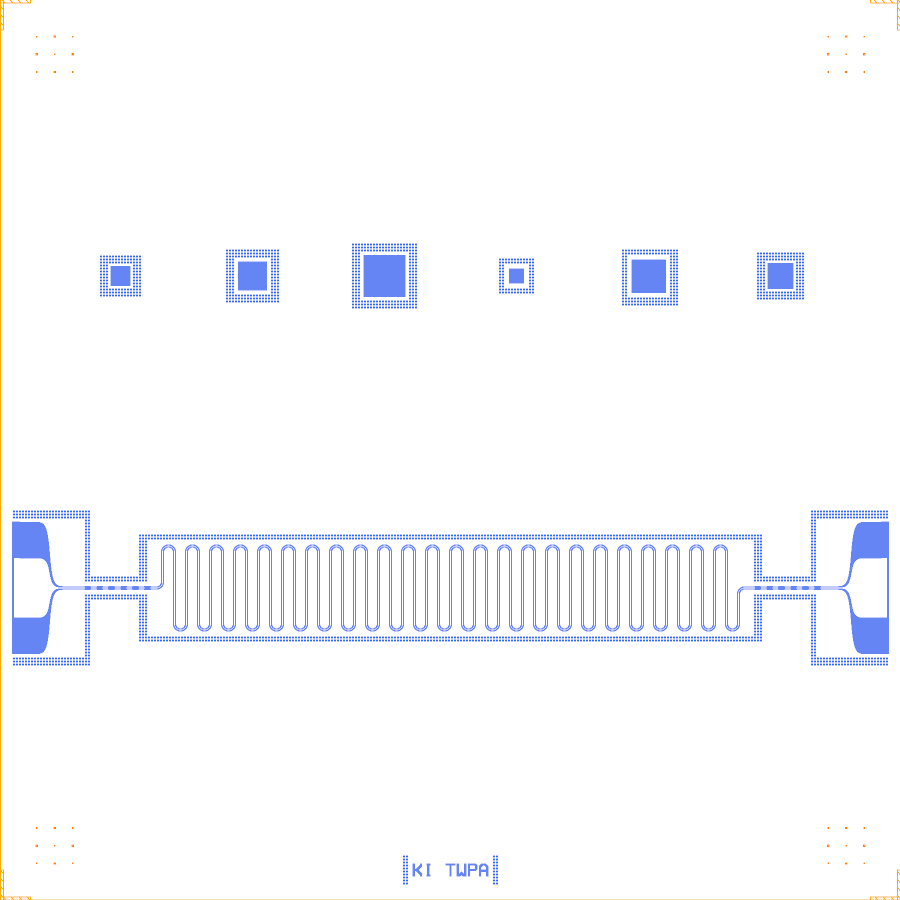

WindowsPath('build/legacy_steps/ki_twpa_structures_3_spirals.png')

In [8]:
with d.batch():
    for x, (name, kind, sr, w, end) in zip(SPIRAL_X, SPIRALS):
        d.add(name, "SpiralLine", at=(x, Y_SPIRAL), spiral_type=kind, spiral_r=sr, width=w, start_angle=0.0,
              end_angle=end, points=1000, metal=True, pocket_margin=POCKET)
L.step_snapshot(d, "3_spirals")

## 6 · Routes: does not apply

No routes: the line is a chain of snapped cells (ports touching), and the spirals are standalone structures.

## 7 · Cheese and centring

**Cheese.** No source cheese: the build draws the PDK band (`cheese: "auto"`) around the 3/0 keep-outs of the line
and the spirals' pockets.

**Centring.** `L.center_circuit` (each axis only if > 50 µm off). The fixed legacy sheet sat 322 µm left of the die
centre (PL 250 µm, PR 1234 µm from their edges); with both pads at the rule the line spans the die symmetrically, so
nothing is left to move in x. Then the design is saved.

centring shift (µm): (0.0, 0.0) | content centre − die centre: (0.0, -39.1) | <Designer ki_twpa_structures: 11 instances, 0 routes, live=False> → examples\designs\legacy\ki_twpa_structures.json


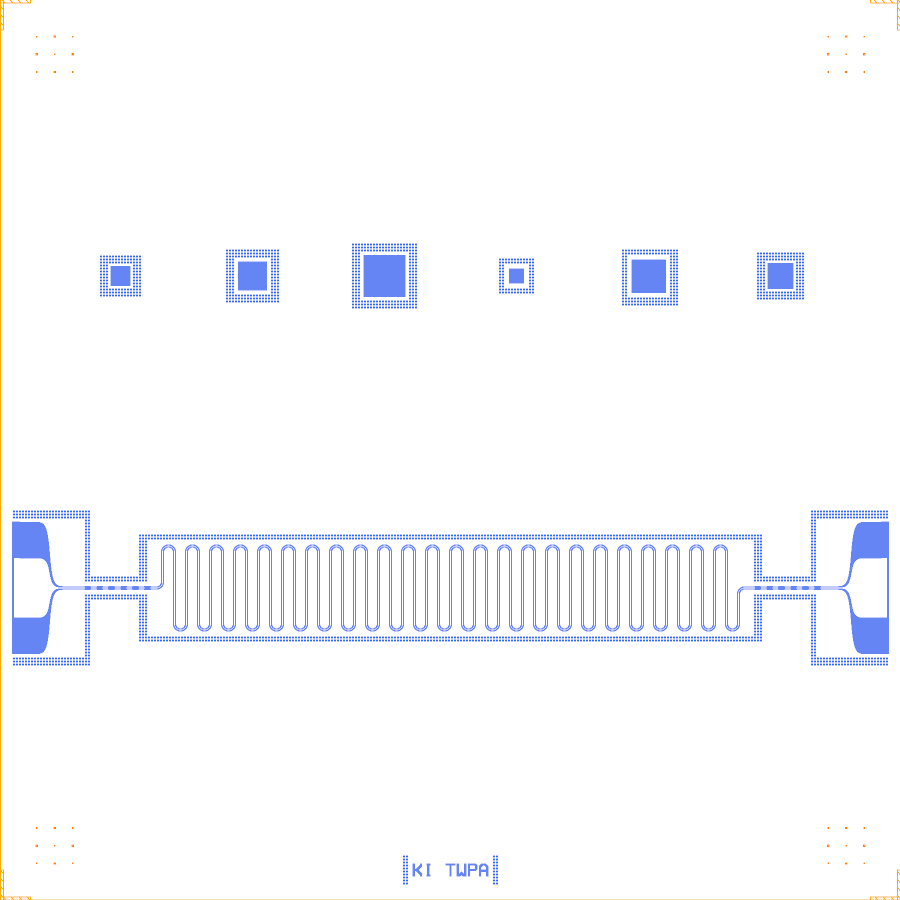

WindowsPath('build/legacy_steps/ki_twpa_structures_4_centred.png')

In [9]:
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
box = L.circuit_box(d)
print("centring shift (µm):", SHIFT, "| content centre − die centre:",
      (round(box.center().x - L.W / 2, 1), round(box.center().y - L.H / 2, 1)), "|", d, "→", DESIGN)
L.step_snapshot(d, "4_centred")

## 8 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Expected (this run): zero errors; 12 `dangling_port` warnings, by design: each spiral's two ends `S1.a` / `S1.b` …
`S6.a` / `S6.b` (not wired on this sheet). No PDK design warnings: both pads at 100 µm (no `pad_edge`; 2 before this
pass), no junctions. `pdk_report`: cheese "PDK band", content centre (+0, −39) µm (within the 50 µm tolerance, so
not moved), junction types "—". The device ID `KI TWPA` sits at the bottom edge centre.

In [10]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning dangling_port S1.a is not connected (no route or snap)
warning dangling_port S1.b is not connected (no route or snap)
warning dangling_port S2.a is not connected (no route or snap)
warning dangling_port S2.b is not connected (no route or snap)
warning dangling_port S3.a is not connected (no route or snap)
warning dangling_port S3.b is not connected (no route or snap)
warning dangling_port S4.a is not connected (no route or snap)
warning dangling_port S4.b is not connected (no route or snap)
warning dangling_port S5.a is not connected (no route or snap)
warning dangling_port S5.b is not connected (no route or snap)
warning dangling_port S6.a is not connected (no route or snap)
warning dangling_port S6.b is not connected (no route or snap)


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, -39) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

The line: one conductor from `PL` to `PR` (each pad a 50 Ω port), the finger sections adding their shunt capacitance
(`CpweFingerLine` model), the meander a CPW segment (its leads included). Each spiral (`SpiralLine`) is an
open-ended line of its drawn centre-line length with the mean turn spacing as its gap (`qcc_length`,
`qcc_turn_gap`).

In [11]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**8 nodes · 11 branches · 0 controls · 12 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `F1.line` | `PL.pad`, `F1.line`, `M1.line`, `F2.line`, `PR.pad` |
| `S1.line` | `S1.line` |
| `S2.line` | `S2.line` |
| `S3.line` | `S3.line` |
| `S4.line` | `S4.line` |
| `S5.line` | `S5.line` |
| `S6.line` | `S6.line` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PL` | R | `F1.line` – `gnd` | 50 Ω |
| `C_F1` | C | `F1.line` – `gnd` | 380 fF |
| `C_F2` | C | `F1.line` – `gnd` | 380 fF |
| `Port_PR` | R | `F1.line` – `gnd` | 50 Ω |
| `M1` | TLres | `F1.line` – `gnd` | lambda/2, 36481 µm, 1.727 GHz |
| `S1` | TLres | `S1.line` – `gnd` | lambda/2, 3103 µm, 19.756 GHz |
| `S2` | TLres | `S2.line` – `gnd` | lambda/2, 4964 µm, 12.500 GHz |
| `S3` | TLres | `S3.line` – `gnd` | lambda/2, 7757 µm, 8.037 GHz |
| `S4` | TLres | `S4.line` – `gnd` | lambda/2, 1357 µm, 45.173 GHz |
| `S5` | TLres | `S5.line` – `gnd` | lambda/2, 3103 µm, 19.987 GHz |
| `S6` | TLres | `S6.line` – `gnd` | lambda/2, 5721 µm, 10.810 GHz |

**Unconnected ports:** `S1.a`, `S1.b`, `S2.a`, `S2.b`, `S3.a`, `S3.b`, `S4.a`, `S4.b`, `S5.a`, `S5.b`, `S6.a`, `S6.b`

**Builder notes:**

- S1: spiral line 3103 µm (gap = mean turn spacing 4.1 µm; rough; kinetic L as a CPW)
- S2: spiral line 4964 µm (gap = mean turn spacing 6.2 µm; rough; kinetic L as a CPW)
- S3: spiral line 7757 µm (gap = mean turn spacing 9.8 µm; rough; kinetic L as a CPW)
- S4: spiral line 1357 µm (gap = mean turn spacing 4 µm; rough; kinetic L as a CPW)
- S5: spiral line 3103 µm (gap = mean turn spacing 18 µm; rough; kinetic L as a CPW)
- S6: spiral line 5721 µm (gap = mean turn spacing 3.8 µm; rough; kinetic L as a CPW)

{'nodes': 7, 'branches': 11, 'controls': 0, 'unconnected': 12}


## 10 · LOM simulation: does not apply — spiral lengths and kinetic inductance instead

There is no qubit or resonator to simulate (the spirals are open lines; a spiral is a lumped L only once a capacitor
closes it, an LER). Instead: the wire length ℓ = the drawn centre-line length (`SpiralLine.qcc_length`, the same value
the LOM line uses), turns and the mean turn gap (`qcc_turn_gap`), and the kinetic inductance L_k = L_□ · ℓ / w for a
few sheet inductances (the KI film is not in the PDK: **0.1 pH/□ ≈ Nb**, 10 and 50 pH/□ ≈ thin NbN / NbTiN — example
values, film to be specified). The geometric inductance is not estimated here. Then the line's length.

In [12]:
def spiral_row(name, kind, sr, w, end):
    prm = dict(spiral_type=kind, spiral_r=sr, width=w, start_angle=0.0, end_angle=end, points=1000)
    length = SpiralLine.qcc_length(prm)
    lk = [lsq * 1e-3 * length / w for lsq in (0.1, 10, 50)]
    return (f"| {name} | {kind} | {sr} / {w} | {end / (2 * math.pi) * (2 if kind == 'double_fermat' else 1):.0f} | "
            f"{length:.0f} | {SpiralLine.qcc_turn_gap(prm):.2f} | " + " / ".join(f"{v:.2f}" for v in lk) + " |")


HEAD = ["| spiral | type | spiral_r / w (µm) | turns | wire ℓ (µm) | turn gap (µm) | L_k @ 0.1 / 10 / 50 pH/□ (nH) |",
        "|---|---|---|---|---|---|---|"]
display(Markdown("\n".join(HEAD + [spiral_row(*s) for s in SPIRALS])))
print("line: pad port to pad port", round(C.port_xy(d, "PR.a")[0] - C.port_xy(d, "PL.a")[0], 1), "µm in x;",
      "sections in x:", {n: round(C.port_xy(d, f"{n}.b")[0] - C.port_xy(d, f"{n}.a")[0], 1) for n in ("F1", "M1", "F2")})

| spiral | type | spiral_r / w (µm) | turns | wire ℓ (µm) | turn gap (µm) | L_k @ 0.1 / 10 / 50 pH/□ (nH) |
|---|---|---|---|---|---|---|
| S1 | double_fermat | 10 / 1.0 | 12 | 3103 | 4.12 | 0.31 / 31.03 / 155.14 |
| S2 | double_fermat | 16 / 2.0 | 12 | 4964 | 6.19 | 0.25 / 24.82 / 124.11 |
| S3 | double_fermat | 25 / 3.0 | 12 | 7757 | 9.79 | 0.26 / 25.86 / 129.28 |
| S4 | double_fermat | 8 / 1.0 | 8 | 1357 | 4.01 | 0.14 / 13.57 / 67.85 |
| S5 | fermat | 20 / 2.0 | 6 | 3103 | 18.47 | 0.16 / 15.51 / 77.57 |
| S6 | double_fermat | 12 / 1.5 | 16 | 5721 | 3.82 | 0.38 / 38.14 / 190.71 |

line: pad port to pad port 6180.0 µm in x; sections in x: {'F1': 598.0, 'M1': 4984.0, 'F2': 598.0}


**Reading the numbers** (this run): the netlist has one line node (PL, F1, M1, F2 and PR are one conductor: two 50 Ω
ports, 380 fF of finger capacitance per finger section, M1 a 36 481 µm CPW) and six open-ended spiral lines of
1357 … 7757 µm. L_k at 10 pH/□ runs from 13.6 nH (S4) to 38.1 nH (S6); at Nb-like 0.1 pH/□ all six are below 0.4 nH,
so on Nb the spirals are geometric inductors and only a high-L_□ film makes them kinetic. The line spans 6180 µm
between the pad ports: F1 598, M1 4984 (24 periods + 2 × 42 µm leads), F2 598 µm.

## 11 · FEM: send the job — does not apply

A structure sheet has no sim groups (no qubit, resonator or port to excite in a cut-out), so `C.export_sims(DESIGN)`
exports nothing and `L.fem_send` says so.

In [13]:
RUN_FEM = False                       # nothing to solve: the sheet has no sim groups
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs) if jobs else "*no sim groups — nothing to export*"))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

*no sim groups — nothing to export*

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

No FEM jobs: this chip has no sim groups (nothing to excite).

## 12 · Bring the results back — does not apply

No jobs, so no results (`L.fem_bring_back` says "No FEM jobs.").

In [14]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM jobs.

## 13 · Iterate: change one property and rebuild

A copy narrows the widest spiral, S3, from 3 to 2 µm (`width`): its path (set by `spiral_r` and the angles) stays, so
the wire length stays and L_k = L_□ · ℓ / w grows with 1 / w; the copy is rebuilt and checked. The copy is not saved.

In [15]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
d2["S3"].set(width=2.0)
s3 = next(s for s in SPIRALS if s[0] == "S3")
display(Markdown("\n".join(HEAD + [spiral_row(*s3), spiral_row("S3 (w 2 µm)", s3[1], s3[2], 2.0, s3[4])])))
print("copy rebuilt:", d2.drc().ok, "(no DRC errors)")

| spiral | type | spiral_r / w (µm) | turns | wire ℓ (µm) | turn gap (µm) | L_k @ 0.1 / 10 / 50 pH/□ (nH) |
|---|---|---|---|---|---|---|
| S3 | double_fermat | 25 / 3.0 | 12 | 7757 | 9.79 | 0.26 / 25.86 / 129.28 |
| S3 (w 2 µm) | double_fermat | 25 / 2.0 | 12 | 7757 | 10.79 | 0.39 / 38.78 / 193.92 |

copy rebuilt: True (no DRC errors)


**Result** (this run): S3 at w = 2 µm keeps its wire length (7757 µm: the path is set by `spiral_r` and the angles),
its mean turn gap grows from 9.79 to 10.79 µm, and L_k grows by 3 / 2 (25.9 → 38.8 nH at 10 pH/□); the copy rebuilds
without DRC errors.

## 14 · Build and export

The design is saved as JSON (`DESIGN`, step 7): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese; every cheese hole of 1/0 is also on 3/0. **Simulation exports** never carry cheese; they drop airbridges
unless asked (`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default): the build already carries the PDK band (the sheet has no cheese of its own), so
the mask keeps it (`cheese_source` "build"). The spirals' metal (`base_metal_addition`) is removed from 1/0 inside
their pockets.

The same from a shell:

```
qcc build examples/designs/legacy/ki_twpa_structures.json                    # layout → build/ki_twpa_structures.oas
qcc mask  examples/designs/legacy/ki_twpa_structures.json          # fab mask with the PDK rules
```

In [16]:
display(Markdown(L.fab_md(d)))

Fab mask: `build/ki_twpa_structures_fab.oas` · cheese source **build** (2589 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 2602 |
| 3/0 | M3 | 2599 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 15 · Snapshots

Full die; the six spirals; each spiral; a finger-loaded section. The spirals' XOR against the legacy `draw.spiral`
is checked in `tests/test_spirals.py`.

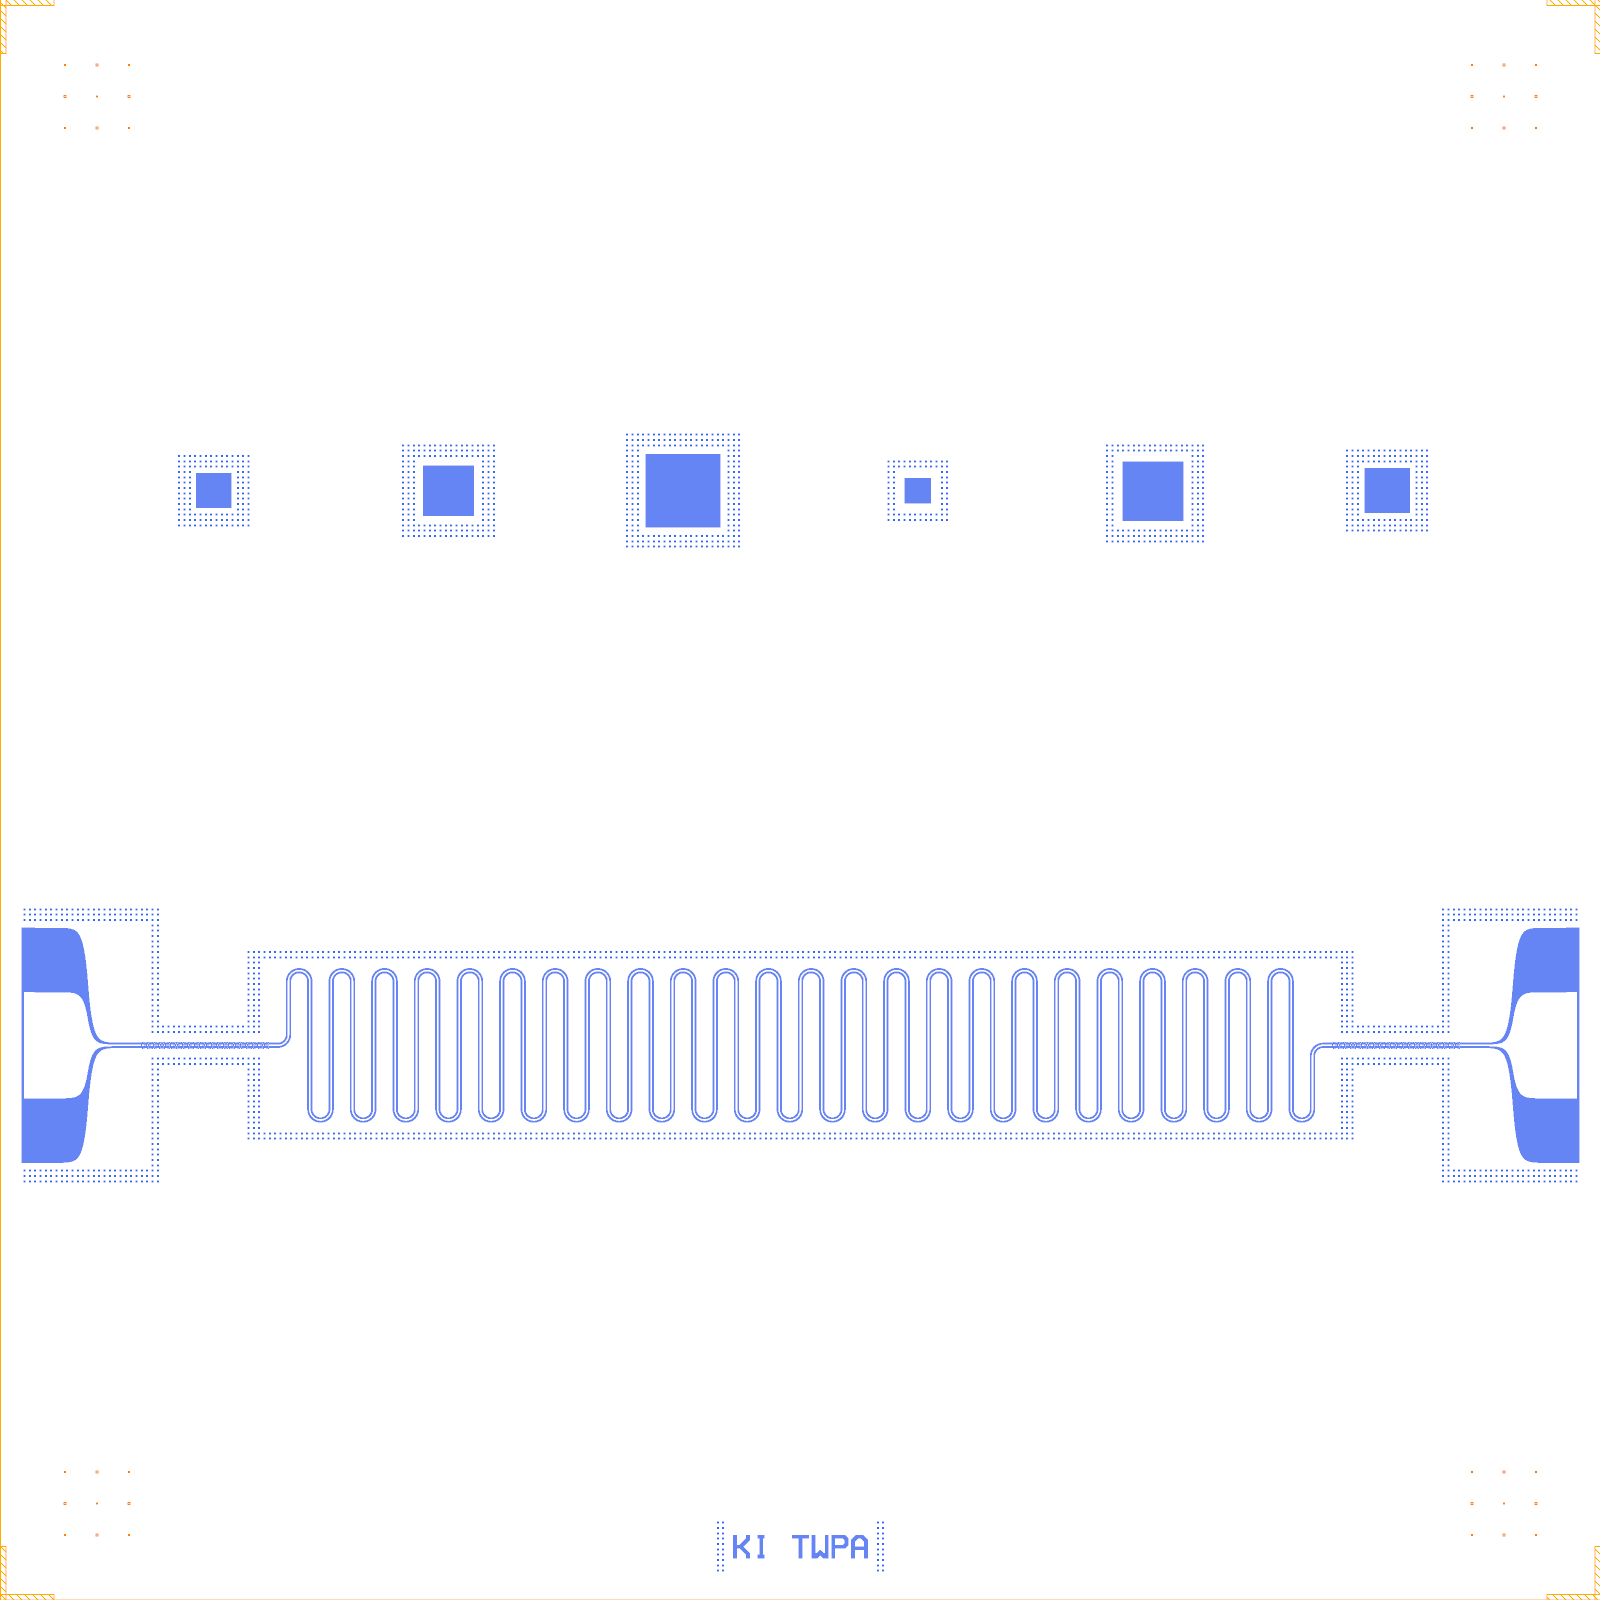

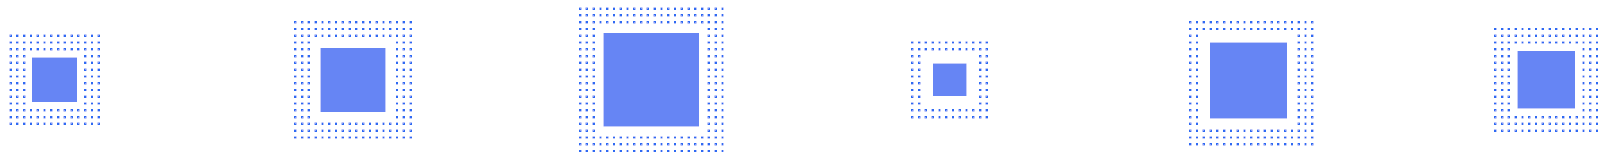

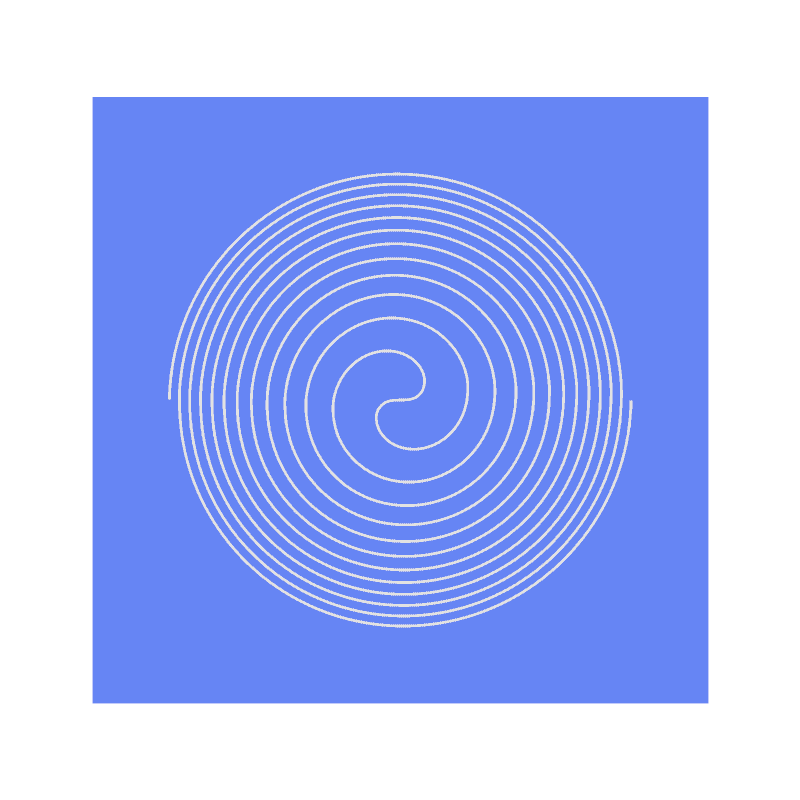

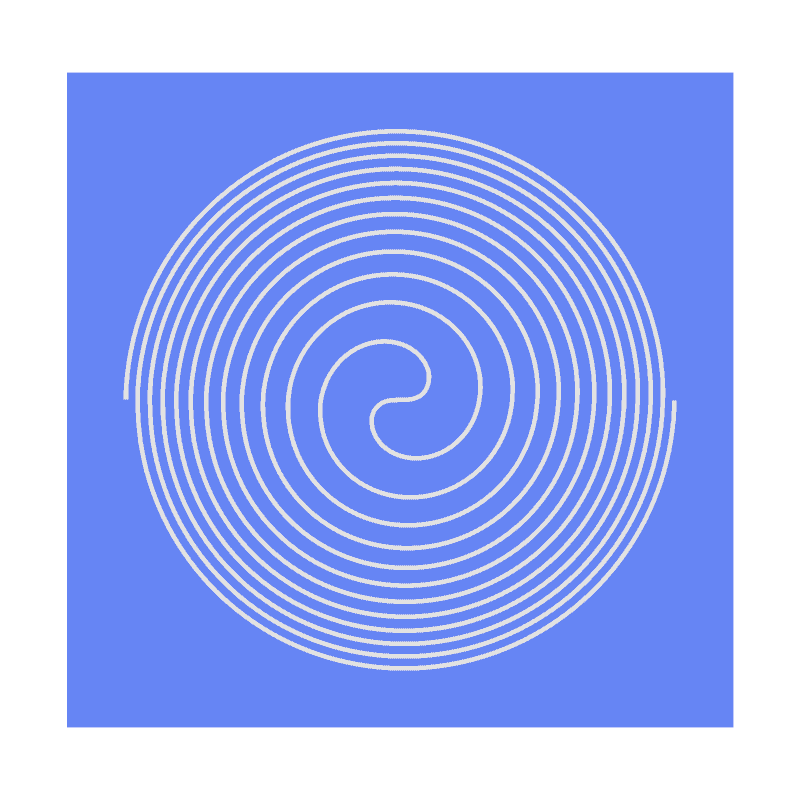

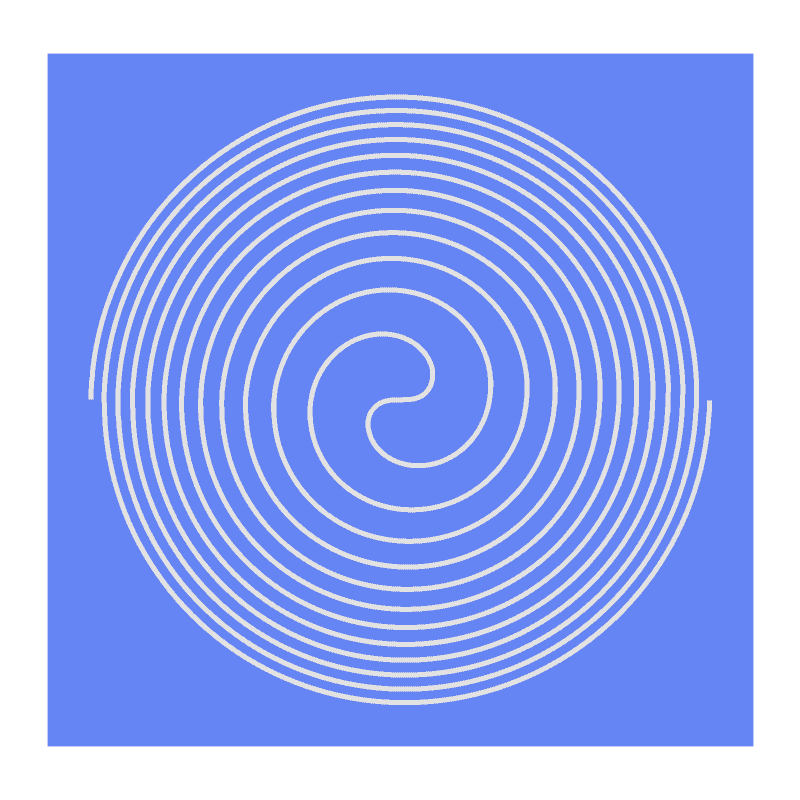

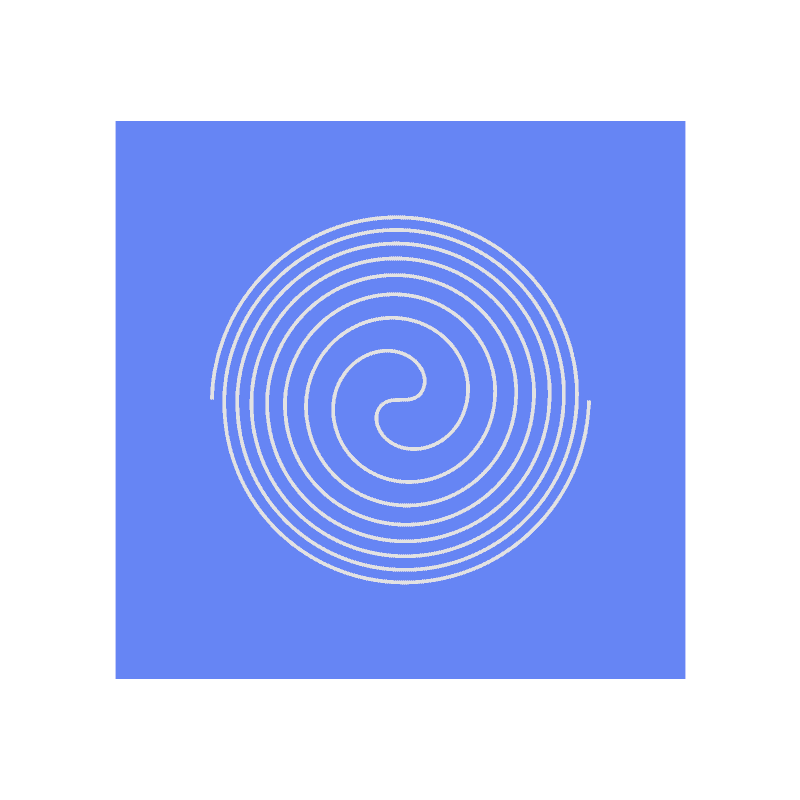

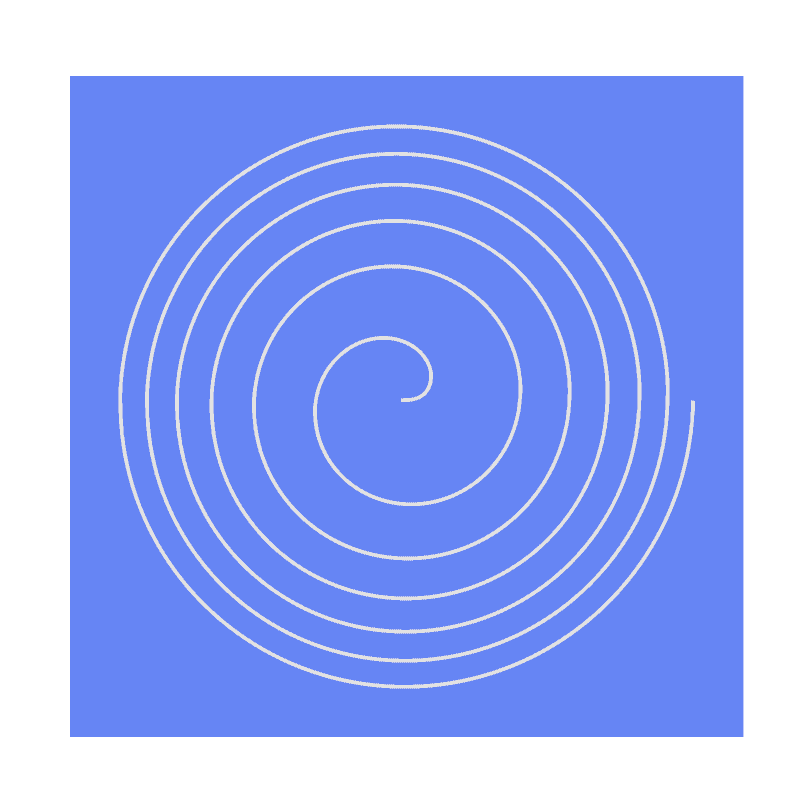

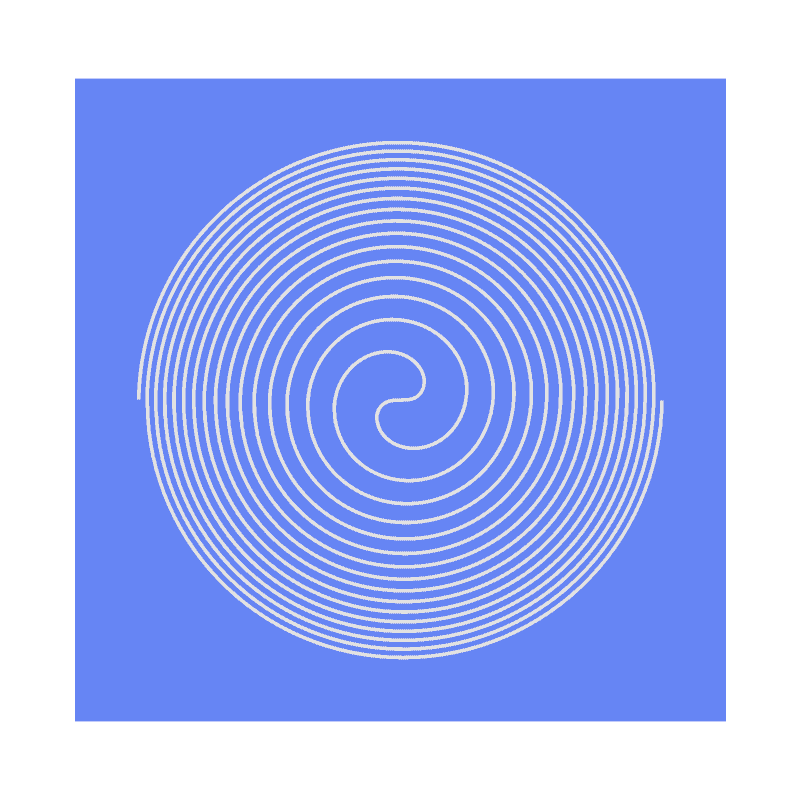

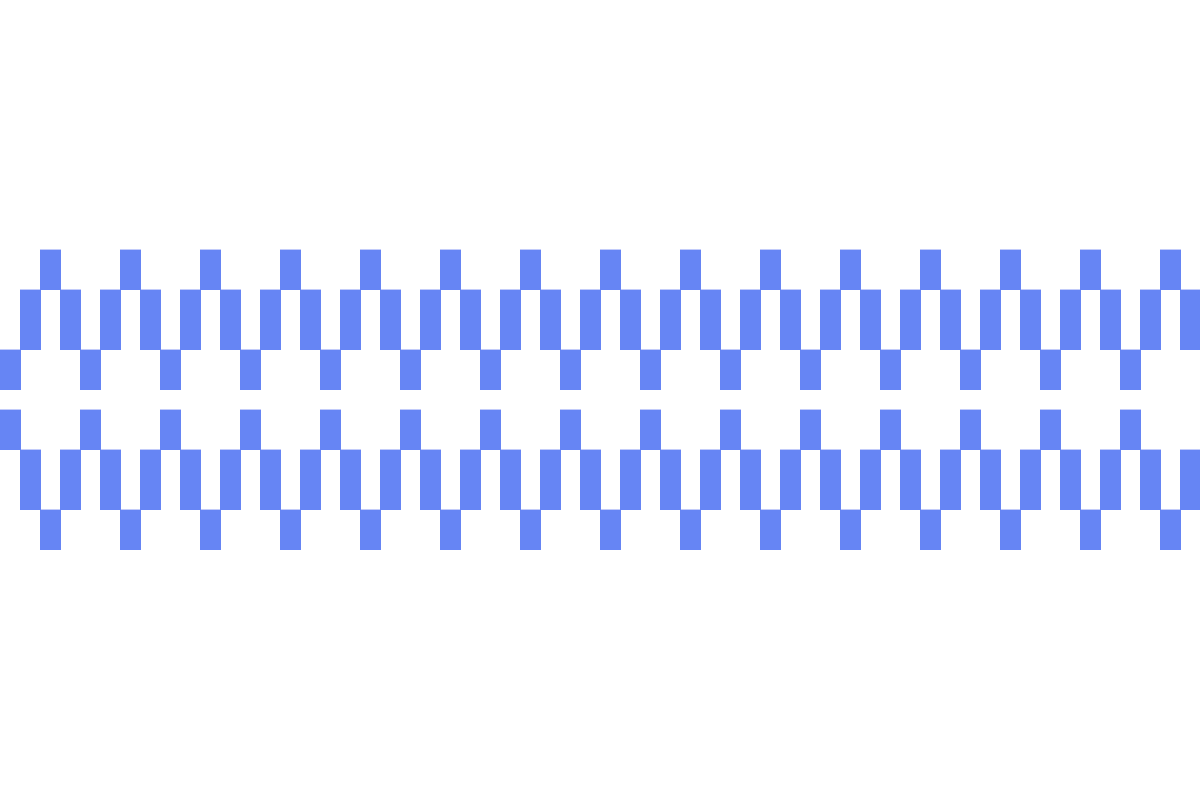

WindowsPath('examples/designs/legacy/ki_twpa_structures_fingers.png')

In [17]:
C.show_snapshot(d, OUT / f"{ID}.png", box=(0, 0, L.W, L.H))
C.show_snapshot(d, OUT / f"{ID}_spirals.png", box=(SPIRAL_X[0] - 200, Y_SPIRAL - 250, SPIRAL_X[-1] + 200, Y_SPIRAL + 250), size=(1600, 160))
for x, (name, kind, sr, w, end) in zip(SPIRAL_X, SPIRALS):
    ro = r_out(kind, sr, end)
    C.show_snapshot(d, OUT / f"{ID}_{name.lower()}.png", box=(x - ro - 45, Y_SPIRAL - ro - 45,
                    x + ro + 45, Y_SPIRAL + ro + 45), size=(800, 800), width=300)
xf, yf = C.port_xy(d, "F1.a")
C.show_snapshot(d, OUT / f"{ID}_fingers.png", box=(xf, yf - 40, xf + 120, yf + 40), size=(1200, 800), width=480)

## 16 · Summary

- **Keeps:** the TWPA-style chain `PL → F1 → M1 → F2 → PR` (one conductor), the legacy `b_pad`, finger and meander
  cells, and the six spirals in their pockets.
- **Differs, by the PDK:** both pads at `pad_edge` = 100 µm (PL by `edge="auto"`, from 250 µm; PR, 1234 µm before,
  by lengthening the meander `M1`: 18 → 24 periods and two 42 µm leads, +1284 µm in x); the line now spans the die
  symmetrically, so the centring has nothing left to move (shift (0, 0); the y offset −39 µm is within tolerance);
  the PDK frame and device ID `KI TWPA`; the PDK cheese band (fab cheese source "build", 2589 holes).
- **Steps that do not apply:** routes, LOM simulation (spiral table instead), FEM.
- **Open:** the KI film's sheet inductance is not in the PDK (example values in step 10); there is no KI / TWPA
  chip source to rebuild.